<a href="https://colab.research.google.com/github/dharsh290807-art/MECHINE-LEARNING/blob/main/ML_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install tensorflow scikit-learn pandas matplotlib seaborn

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    accuracy_score, precision_score, recall_score, f1_score
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
uploaded = files.upload()  # Select your CSV file
CSV_PATH = next(iter(uploaded))

df = pd.read_csv(CSV_PATH, low_memory=False)
df.columns = df.columns.astype(str).str.strip()

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/Jehuty4949/NSL_KDD/master/KDDTrain%2B.csv"

column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised", "root_shell",
    "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

df = pd.read_csv(url, header=None, names=column_names)

print("Dataset shape:", df.shape)
display(df.head())
print("\nLabels:")
print(df["label"].value_counts())

Dataset shape: (125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21



Labels:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Clean up label text for consistent display
df["label"] = df["label"].astype(str).str.strip().str.lower()

print("Rows and columns:", df.shape)
print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nNumeric summary:")
display(df.describe(include="number").T)

print("\nCategorical feature values:")
for col in ["protocol_type", "service", "flag"]:
    print(f"\n{col}: {df[col].nunique()} unique values")

Rows and columns: (125973, 43)

Data types:
int64      24
float64    15
object      4
Name: count, dtype: int64

Missing values:
0

Duplicate rows: 0

Label counts:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.00,0.00,0.00,7.479000e+03



Categorical feature values:

protocol_type: 3 unique values

service: 70 unique values

flag: 11 unique values


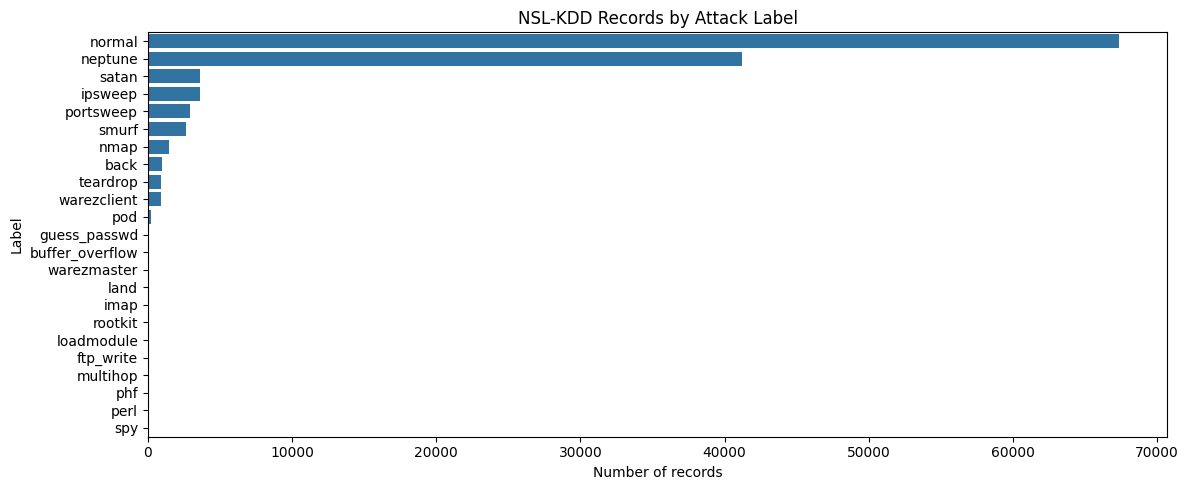

In [ ]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="label", order=df["label"].value_counts().index)
plt.title("NSL-KDD Records by Attack Label")
plt.xlabel("Number of records")
plt.ylabel("Label")
plt.tight_layout()
plt.show()

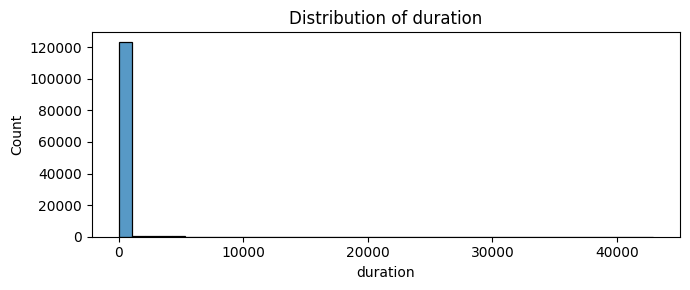

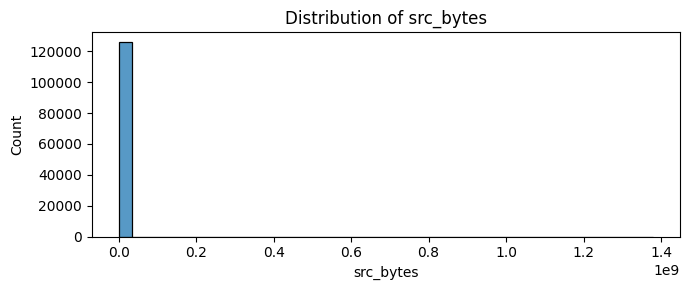

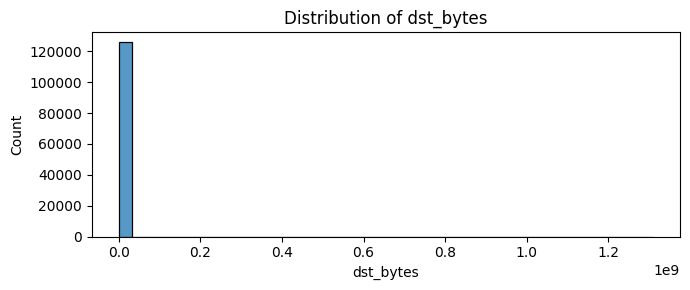

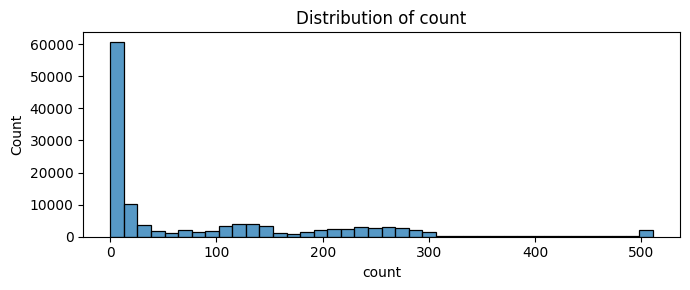

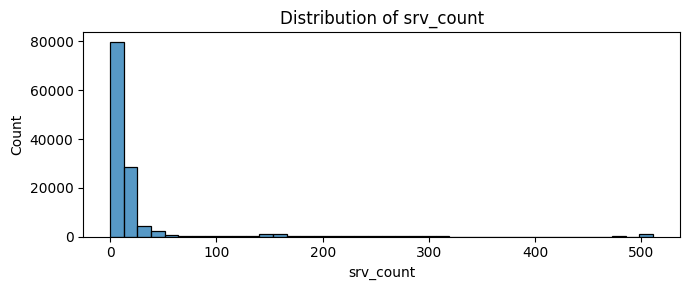

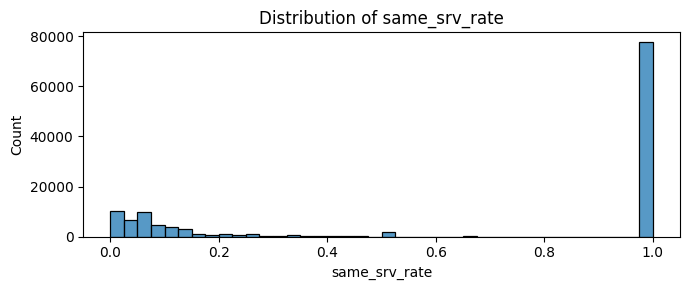

In [ ]:
numeric_features = [
    "duration", "src_bytes", "dst_bytes",
    "count", "srv_count", "same_srv_rate"
]

for col in numeric_features:
    plt.figure(figsize=(7, 3))
    sns.histplot(data=df, x=col, bins=40)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

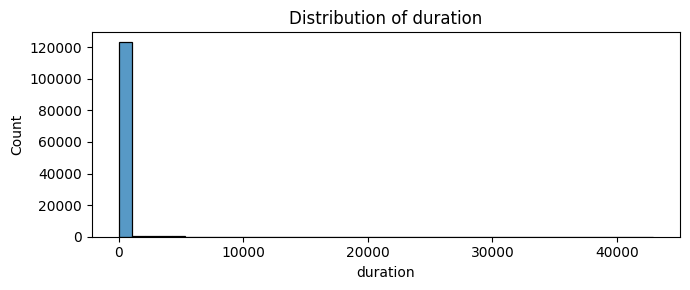

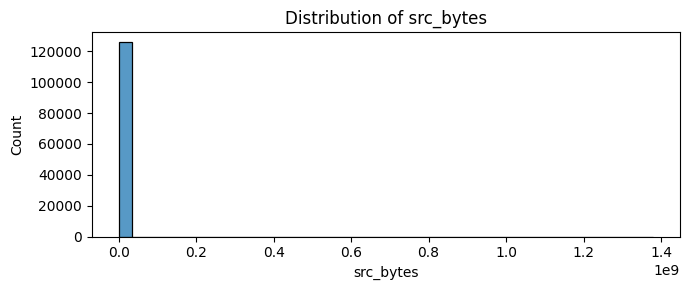

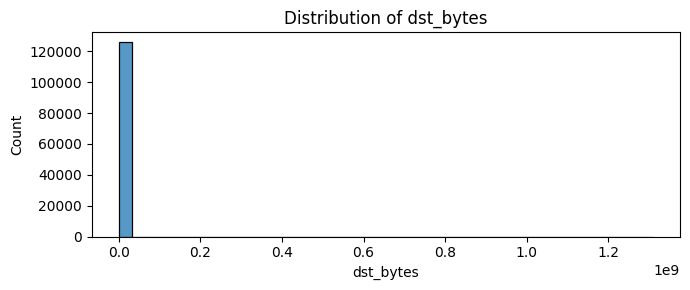

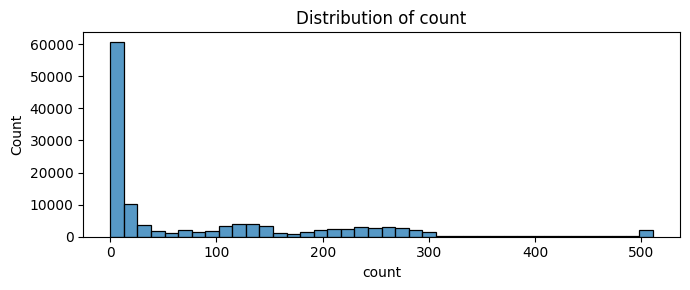

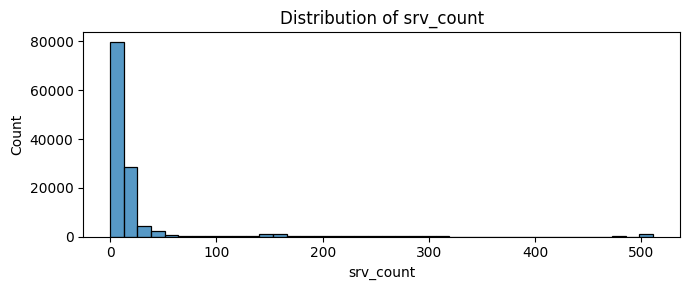

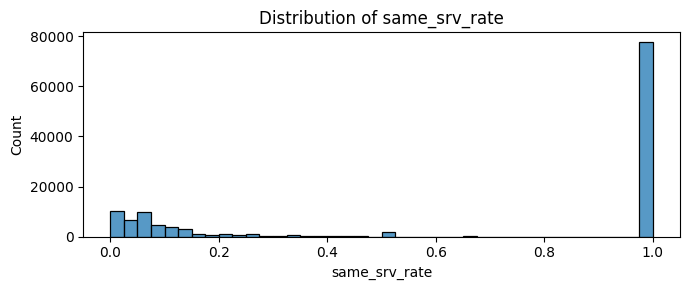

In [ ]:
numeric_features = [
    "duration", "src_bytes", "dst_bytes",
    "count", "srv_count", "same_srv_rate"
]

for col in numeric_features:
    plt.figure(figsize=(7, 3))
    sns.histplot(data=df, x=col, bins=40)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

In [ ]:
df["binary_label"] = (df["label"] != "normal").astype(int)

print(df["binary_label"].value_counts().rename({
    0: "Normal",
    1: "Attack"
}))

binary_label
Normal    67343
Attack    58630
Name: count, dtype: int64


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Remove rows with missing labels, then remove duplicates
df = df.dropna(subset=["binary_label"]).drop_duplicates().copy()

# Target: 0 = Normal, 1 = Attack
y = df["binary_label"].astype(int)

# Drop the text label and dataset difficulty score from model inputs
X = df.drop(columns=["label", "binary_label", "difficulty"])

# Encode categorical input columns as numbers
categorical_columns = ["protocol_type", "service", "flag"]
X = pd.get_dummies(X, columns=categorical_columns, dtype=int)

# Replace infinite values and fill missing values
X = X.replace([float("inf"), -float("inf")], pd.NA)
X = X.fillna(X.median()).fillna(0)

# Split before scaling so the scaler is fitted only on training data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

print("Training features:", X_train_scaled.shape)
print("Testing features:", X_test_scaled.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (100778, 122)
Testing features: (25195, 122)
Training labels: (100778,)
Testing labels: (25195,)


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Keep only normal records for autoencoder training
X_normal = X_train_scaled[y_train.to_numpy() == 0]

# Set aside some normal records to choose the anomaly threshold
X_ae_train, X_ae_val = train_test_split(
    X_normal,
    test_size=0.10,
    random_state=42
)

number_of_features = X_train_scaled.shape[1]

# Build the autoencoder
inputs = tf.keras.Input(shape=(number_of_features,))
x = tf.keras.layers.Dense(64, activation="relu")(inputs)
x = tf.keras.layers.Dense(24, activation="relu")(x)
x = tf.keras.layers.Dense(64, activation="relu")(x)
outputs = tf.keras.layers.Dense(number_of_features)(x)

autoencoder = tf.keras.Model(inputs, outputs)
autoencoder.compile(optimizer="adam", loss="mse")

# Train it to reconstruct normal records
autoencoder.fit(
    X_ae_train,
    X_ae_train,
    validation_data=(X_ae_val, X_ae_val),
    epochs=20,
    batch_size=256,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4097 - val_loss: 0.1601
Epoch 2/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2230 - val_loss: 0.0938
Epoch 3/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1618 - val_loss: 0.0657
Epoch 4/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1299 - val_loss: 0.0570
Epoch 5/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1052 - val_loss: 0.0508
Epoch 6/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0869 - val_loss: 0.0573
Epoch 7/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0761 - val_loss: 0.0426
Epoch 8/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0646 - val_loss: 0.0364
Epoch 9/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0603 - val_loss: 0.0339
Epoch 10/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0602 - val_loss: 0.0325
Epoch 11/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0455 - val_loss: 0.0310
Epoch 12/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

In [ ]:
# Reconstruction errors for normal validation records
val_reconstruction = autoencoder.predict(X_ae_val, verbose=0)
val_errors = np.mean((X_ae_val - val_reconstruction) ** 2, axis=1)

# Flag the top 5% of normal validation errors as anomalous
threshold = np.percentile(val_errors, 95)
print("Anomaly threshold:", threshold)

# Test predictions: 0 = Normal, 1 = Attack
test_reconstruction = autoencoder.predict(X_test_scaled, verbose=0)
test_errors = np.mean((X_test_scaled - test_reconstruction) ** 2, axis=1)
ae_predictions = (test_errors > threshold).astype(int)

print(classification_report(
    y_test,
    ae_predictions,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, ae_predictions))

Anomaly threshold: 0.07481462
              precision    recall  f1-score   support

      Normal       0.96      0.95      0.95     13469
      Attack       0.94      0.96      0.95     11726

    accuracy                           0.95     25195
   macro avg       0.95      0.95      0.95     25195
weighted avg       0.95      0.95      0.95     25195

Confusion matrix:
[[12740   729]
 [  514 11212]]


In [ ]:
import tensorflow as tf
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# LSTM input shape: (records, time steps, features)
# Here each record has one time step.
X_train_lstm = X_train_scaled.reshape(
    X_train_scaled.shape[0], 1, X_train_scaled.shape[1]
)
X_test_lstm = X_test_scaled.reshape(
    X_test_scaled.shape[0], 1, X_test_scaled.shape[1]
)

lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1, X_train_scaled.shape[1])),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = lstm_model.fit(
    X_train_lstm,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=256,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9554 - loss: 0.1757 - val_accuracy: 0.9780 - val_loss: 0.0592
Epoch 2/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9844 - loss: 0.0402 - val_accuracy: 0.9895 - val_loss: 0.0316
Epoch 3/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9905 - loss: 0.0280 - val_accuracy: 0.9916 - val_loss: 0.0284
Epoch 4/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9922 - loss: 0.0249 - val_accuracy: 0.9928 - val_loss: 0.0249
Epoch 5/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9934 - loss: 0.0215 - val_accuracy: 0.9937 - val_loss: 0.0220
Epoch 6/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9933 - loss: 0.0196 - val_accuracy: 0.9939 - val_loss: 0.0205
Epoch 7/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9935 - loss: 0.0185 - val_accuracy: 0.9939 - val_loss: 0.0206
Epoch 8/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9941 - loss: 0.0175 - val_accuracy: 0

In [ ]:
# Predict attack probabilities and convert them to classes
lstm_probabilities = lstm_model.predict(X_test_lstm, verbose=0).ravel()
lstm_predictions = (lstm_probabilities >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, lstm_predictions))
print("Precision:", precision_score(y_test, lstm_predictions, zero_division=0))
print("Recall   :", recall_score(y_test, lstm_predictions, zero_division=0))
print("F1-score :", f1_score(y_test, lstm_predictions, zero_division=0))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC  :", roc_auc_score(y_test, lstm_probabilities))

print("\nClassification report:")
print(classification_report(
    y_test,
    lstm_predictions,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, lstm_predictions))

Accuracy : 0.9942845802738639
Precision: 0.9937755798090041
Recall   : 0.993945079310933
F1-score : 0.9938603223330775
ROC-AUC  : 0.9998050874480762

Classification report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99     13469
      Attack       0.99      0.99      0.99     11726

    accuracy                           0.99     25195
   macro avg       0.99      0.99      0.99     25195
weighted avg       0.99      0.99      0.99     25195

Confusion matrix:
[[13396    73]
 [   71 11655]]


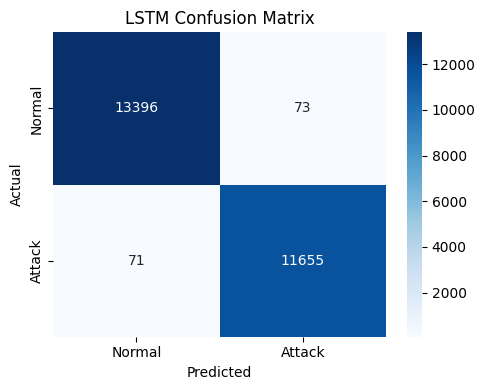

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, lstm_predictions)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LSTM Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import os
import json
import joblib
from google.colab import files

os.makedirs("ddos_project", exist_ok=True)

# Save the trained models
lstm_model.save("ddos_project/lstm_model.keras")
autoencoder.save("ddos_project/autoencoder.keras")

# Save the scaler and the exact feature order used during training
joblib.dump(scaler, "ddos_project/scaler.joblib")
joblib.dump(X.columns.tolist(), "ddos_project/feature_columns.joblib")

# Save the autoencoder's anomaly threshold
with open("ddos_project/autoencoder_threshold.json", "w") as f:
    json.dump({"threshold": float(threshold)}, f)

# Package the files for download
!zip -qr ddos_project.zip ddos_project
files.download("ddos_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install gradio
import gradio as gr

In [ ]:
feature_columns = X.columns.tolist()

def predict_csv(file_path):
    if file_path is None:
        return pd.DataFrame({"message": ["Upload a CSV file."]})

    new_df = pd.read_csv(file_path, header=None, names=column_names)

    # Keep only input features; remove labels and dataset difficulty score
    new_X = new_df.drop(
        columns=["label", "difficulty"],
        errors="ignore"
    )

    # Apply the same categorical encoding used during training
    new_X = pd.get_dummies(
        new_X,
        columns=["protocol_type", "service", "flag"],
        dtype=int
    )

    # Match the training features and their exact order
    new_X = new_X.reindex(columns=feature_columns, fill_value=0)

    # Make values numeric and handle missing or infinite values
    new_X = new_X.replace([np.inf, -np.inf], np.nan)
    new_X = new_X.fillna(0)

    new_X_scaled = scaler.transform(new_X).astype("float32")
    new_X_lstm = new_X_scaled.reshape(
        new_X_scaled.shape[0], 1, new_X_scaled.shape[1]
    )

    probabilities = lstm_model.predict(new_X_lstm, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    return pd.DataFrame({
        "prediction": np.where(predictions == 1, "Attack", "Normal"),
        "attack_probability": probabilities
    })

demo = gr.Interface(
    fn=predict_csv,
    inputs=gr.File(label="Upload an NSL-KDD CSV", type="filepath"),
    outputs=gr.Dataframe(label="Predictions"),
    title="Network Intrusion Detection Demo",
    description="Upload NSL-KDD records to predict Normal or Attack."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c6b957990f5c042834.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Autoencoder",
        "Accuracy": accuracy_score(y_test, ae_predictions),
        "Precision": precision_score(y_test, ae_predictions, zero_division=0),
        "Recall": recall_score(y_test, ae_predictions, zero_division=0),
        "F1-score": f1_score(y_test, ae_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, -test_errors)
    },
    {
        "Model": "LSTM",
        "Accuracy": accuracy_score(y_test, lstm_predictions),
        "Precision": precision_score(y_test, lstm_predictions, zero_division=0),
        "Recall": recall_score(y_test, lstm_predictions, zero_division=0),
        "F1-score": f1_score(y_test, lstm_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, lstm_probabilities)
    }
])

display(comparison.round(4))
comparison.to_csv("model_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Autoencoder,0.9507,0.9389,0.9562,0.9475,0.0149
1,LSTM,0.9943,0.9938,0.9939,0.9939,0.9998


In [ ]:
summary = f"""
PROJECT: Network Intrusion Detection Using an Autoencoder and LSTM

DATASET
Rows after preprocessing: {len(X)}
Input features after encoding: {X.shape[1]}
Normal records: {(y == 0).sum()}
Attack records: {(y == 1).sum()}
Training records: {len(y_train)}
Testing records: {len(y_test)}

MODEL RESULTS
{comparison.round(4).to_string(index=False)}

LIMITATIONS
NSL-KDD is a general network intrusion dataset, not a modern DDoS-only dataset.
The LSTM uses one record per input sequence and does not learn temporal traffic patterns.
The Colab Gradio deployment link is temporary and only works while the runtime is active.
"""

print(summary)

with open("project_results.txt", "w", encoding="utf-8") as f:
    f.write(summary)

from google.colab import files
files.download("project_results.txt")


PROJECT: Network Intrusion Detection Using an Autoencoder and LSTM

DATASET
Rows after preprocessing: 125973
Input features after encoding: 122
Normal records: 67343
Attack records: 58630
Training records: 100778
Testing records: 25195

MODEL RESULTS
      Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Autoencoder    0.9507     0.9389  0.9562    0.9475   0.0149
       LSTM    0.9943     0.9938  0.9939    0.9939   0.9998

LIMITATIONS
NSL-KDD is a general network intrusion dataset, not a modern DDoS-only dataset.
The LSTM uses one record per input sequence and does not learn temporal traffic patterns.
The Colab Gradio deployment link is temporary and only works while the runtime is active.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>